In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost jupyter streamlit

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 621.2 kB/s eta 0:02:43
   ---------------------------------------- 0.5/101.7 MB 621.2 kB/s eta 0:02:43
   ---------------------------------------- 0.8/101.7 MB 671.3 kB/s eta 0:02:31
   ---------------------------------------- 0.8/101.7 MB 671.3 kB/s eta 0:02:31
   ---------------------------------------- 1.0/101.7 MB 739.8 kB/s eta 0:02:17
    --------------------------------------- 1.3/101.7 MB 798.6 kB/s eta 0:02:06
    --------------------------------------- 1.6/101.7 MB 856.1 kB/s eta 0:01:57
    --------------------------------------- 1.8/101.7 MB 915.0 kB/s eta 0:01:50
    -


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
os.makedirs("output", exist_ok=True)   # folder untuk menyimpan gambar & tabel hasil
RANDOM_STATE = 42
PALETTE = {"Tidak Hujan": "#E8A33D", "Hujan": "#2F6DB5"}   # warna konsisten untuk tiap kelas

In [ ]:

# 1. Import library pandas
import pandas as pd

# 2. Impor dataset ke Python
df_raw = pd.read_csv("kolkata_weather_jan_june_2026.csv")

# 3. Tampilkan struktur data
print("Shape data (Baris, Kolom):", df_raw.shape)

print("\n--- 5 Data Teratas ---")
display(df_raw.head())

print("\n--- Informasi Tipe Data ---")
df_raw.info()

print("\n--- Ringkasan Statistik ---")
display(df_raw.describe(include="all"))


NameError: name 'df' is not defined

In [ ]:
df = df_raw.copy()

# --- Fitur turunan ---
df["time"] = pd.to_datetime(df["time"])
df["sunrise"] = pd.to_datetime(df["sunrise"])
df["sunset"] = pd.to_datetime(df["sunset"])
df["daylight_hours"] = (df["sunset"] - df["sunrise"]).dt.total_seconds() / 3600
df["sunshine_hours"] = df["sunshine_duration"] / 3600
df["temp_range"] = df["temperature_2m_max"] - df["temperature_2m_min"]
df["bulan"] = df["time"].dt.month

def get_musim(bulan):
    if bulan in (12, 1, 2):
        return "Dingin"
    if bulan in (3, 4, 5):
        return "Panas"
    if bulan in (6, 7, 8, 9):
        return "Monsun"
    return "Pasca-Monsun"

MUSIM_LIST = ["Dingin", "Panas", "Monsun", "Pasca-Monsun"]
df["musim"] = pd.Categorical(df["bulan"].map(get_musim), categories=MUSIM_LIST)

# --- Target ---
df["hujan"] = (df["rain_sum"] > 0).astype(int)
df["label"] = df["hujan"].map({0: "Tidak Hujan", 1: "Hujan"})

# --- Daftar fitur ---
NUM_FEATURES = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
                "temp_range", "wind_speed_10m_max", "wind_gusts_10m_max",
                "wind_direction_10m_dominant", "sunshine_hours", "daylight_hours"]
CAT_FEATURES = ["musim"]
LEAKAGE_COLS = ["weather_code", "precipitation_sum", "rain_sum", "precipitation_hours"]

print("Fitur numerik   :", NUM_FEATURES)
print("Fitur kategorik :", CAT_FEATURES)
print("Kolom dibuang (leakage):", LEAKAGE_COLS)
print()
print("Distribusi target:")
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

Fitur numerik   : ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'temp_range', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_hours', 'daylight_hours']
Fitur kategorik : ['musim']
Kolom dibuang (leakage): ['weather_code', 'precipitation_sum', 'rain_sum', 'precipitation_hours']

Distribusi target:
label
Hujan          1021
Tidak Hujan     806
Name: count, dtype: int64
label
Hujan          0.559
Tidak Hujan    0.441
Name: proportion, dtype: float64


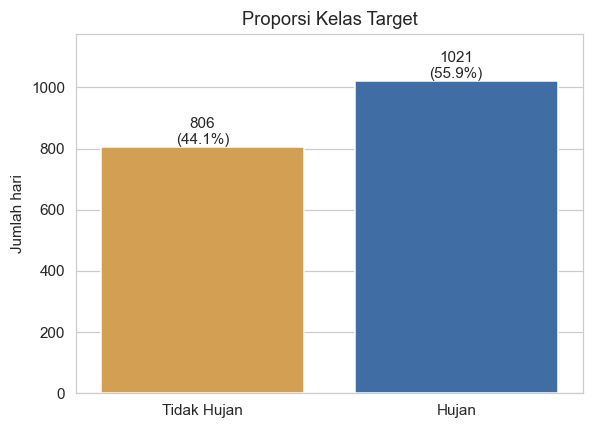

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 4))
urutan = ["Tidak Hujan", "Hujan"]
sns.countplot(data=df, x="label", hue="label", order=urutan, legend=False,
              palette=PALETTE, ax=ax)
for p in ax.patches:
    n = int(p.get_height())
    ax.annotate(f"{n}\n({n / len(df):.1%})", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Proporsi Kelas Target")
ax.set_xlabel("")
ax.set_ylabel("Jumlah hari")
ax.set_ylim(0, df["label"].value_counts().max() * 1.15)
plt.tight_layout()
plt.savefig("output/01_proporsi_kelas.png", bbox_inches="tight")
plt.show()

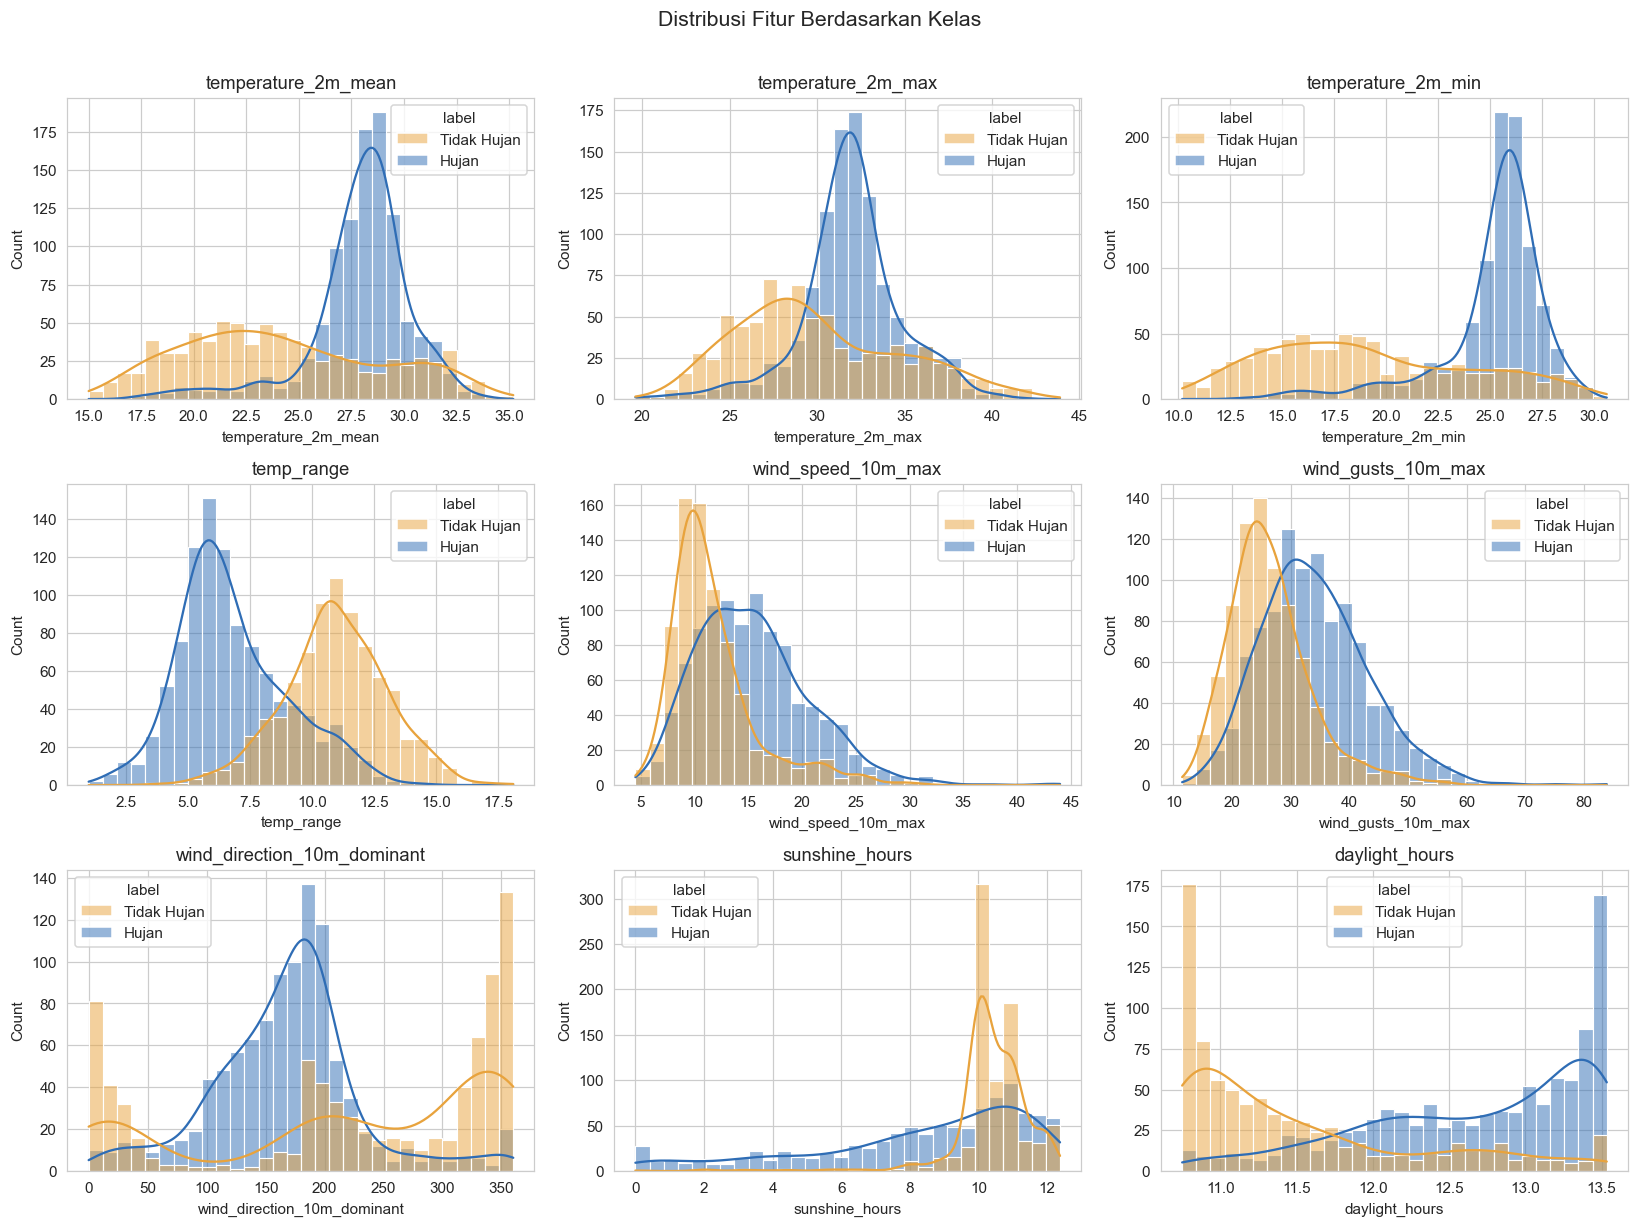

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, fitur in zip(axes.ravel(), NUM_FEATURES):
    sns.histplot(data=df, x=fitur, hue="label", hue_order=urutan, kde=True, bins=30,
                 palette=PALETTE, ax=ax)
    ax.set_title(fitur)
plt.suptitle("Distribusi Fitur Berdasarkan Kelas", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig("output/02_histogram_fitur.png", bbox_inches="tight")
plt.show()

In [ ]:
cek = df[NUM_FEATURES + CAT_FEATURES + ["hujan"]]
missing = cek.isna().sum()
print("Jumlah missing value per kolom:")
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value pada semua fitur dan target.")
print("\nJumlah baris duplikat:", df.duplicated().sum())

if missing.sum() > 0:
    # Jika ada, isi dengan median (numerik) / modus (kategorik).
    # Catatan: untuk data nyata yang bermasalah, sebaiknya SimpleImputer di-fit hanya pada data latih.
    for k in NUM_FEATURES:
        df[k] = df[k].fillna(df[k].median())
    for k in CAT_FEATURES:
        df[k] = df[k].fillna(df[k].mode()[0])

Jumlah missing value per kolom:
Tidak ada missing value pada semua fitur dan target.

Jumlah baris duplikat: 0


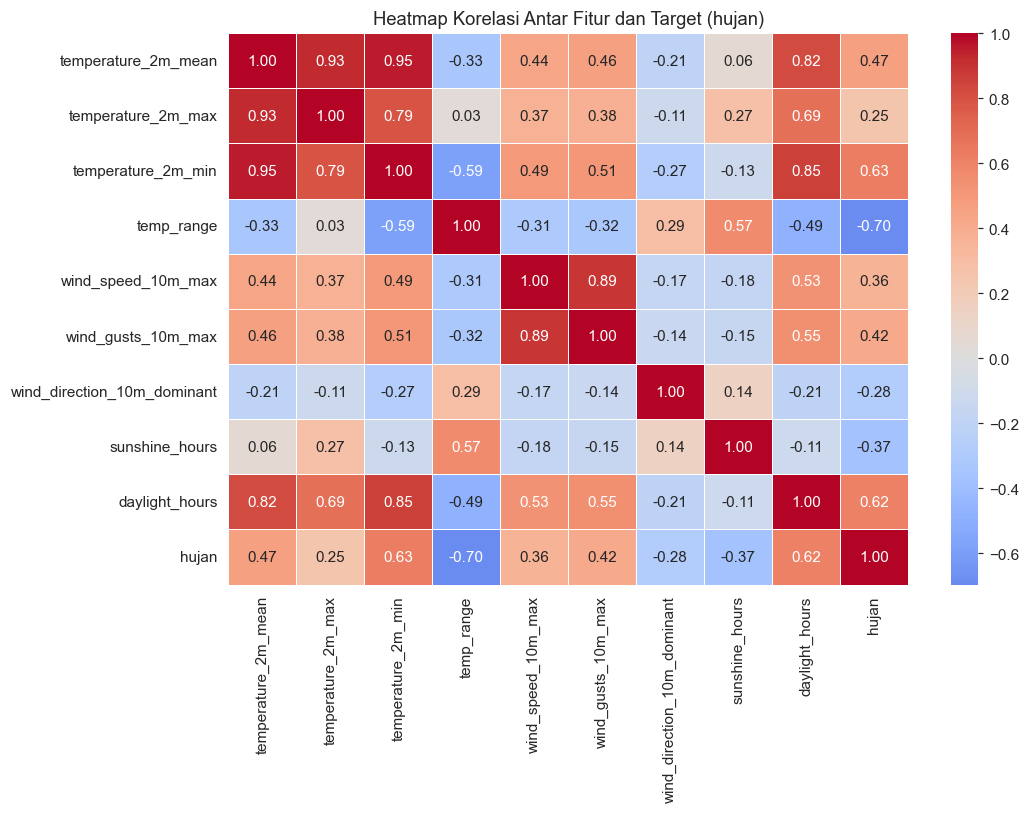

Korelasi tiap fitur terhadap target (terurut):
temperature_2m_min             0.626
daylight_hours                 0.615
temperature_2m_mean            0.467
wind_gusts_10m_max             0.418
wind_speed_10m_max             0.361
temperature_2m_max             0.246
wind_direction_10m_dominant   -0.282
sunshine_hours                -0.370
temp_range                    -0.696
Name: hujan, dtype: float64


In [ ]:
korelasi = df[NUM_FEATURES + ["hujan"]].corr()

plt.figure(figsize=(10, 7.5))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Heatmap Korelasi Antar Fitur dan Target (hujan)")
plt.tight_layout()
plt.savefig("output/04_heatmap_korelasi.png", bbox_inches="tight")
plt.show()

print("Korelasi tiap fitur terhadap target (terurut):")
print(korelasi["hujan"].drop("hujan").sort_values(ascending=False).round(3))

In [ ]:
# One-Hot Encoding fitur kategorik
X = pd.concat([df[NUM_FEATURES],
               pd.get_dummies(df["musim"], prefix="musim", dtype=int)], axis=1)
y = df["hujan"]

print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)
print("Kolom fitur akhir:", list(X.columns))
X.head()

Bentuk X: (1827, 13) | Bentuk y: (1827,)
Kolom fitur akhir: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'temp_range', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_hours', 'daylight_hours', 'musim_Dingin', 'musim_Panas', 'musim_Monsun', 'musim_Pasca-Monsun']


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,temp_range,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_hours,daylight_hours,musim_Dingin,musim_Panas,musim_Monsun,musim_Pasca-Monsun
0,29.9,33.4,28.0,5.4,23.7,46.1,206,5.788267,13.500000,0,0,1,0
1,29.8,33.4,27.8,5.6,19.1,37.1,193,5.955344,13.500000,0,0,1,0
2,29.2,32.2,27.8,4.4,18.7,33.8,209,3.414311,13.483333,0,0,1,0
3,29.2,32.9,27.3,5.6,15.5,32.0,202,8.190736,13.483333,0,0,1,0
4,28.6,32.1,26.9,5.2,12.0,29.5,180,11.429294,13.483333,0,0,1,0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Data latih : {X_train.shape[0]} baris ({X_train.shape[0] / len(X):.0%})")
print(f"Data uji   : {X_test.shape[0]} baris ({X_test.shape[0] / len(X):.0%})")
print("\nProporsi hujan pada data latih:", round(y_train.mean(), 3))
print("Proporsi hujan pada data uji  :", round(y_test.mean(), 3))

# --- Pemeriksaan data leakage ---
assert not any(c in X.columns for c in LEAKAGE_COLS), "Ada kolom leakage di fitur!"
assert len(set(X_train.index) & set(X_test.index)) == 0, "Data latih dan uji beririsan!"
print("\nPemeriksaan leakage lolos: tidak ada kolom bocor dan tidak ada baris yang tumpang tindih.")

Data latih : 1461 baris (80%)
Data uji   : 366 baris (20%)

Proporsi hujan pada data latih: 0.559
Proporsi hujan pada data uji  : 0.56

Pemeriksaan leakage lolos: tidak ada kolom bocor dan tidak ada baris yang tumpang tindih.


In [ ]:
# ============================================================
# NORMALISASI DATA DAN MENYIMPAN KE CSV
# ============================================================

from sklearn.preprocessing import StandardScaler

# Membuat scaler
scaler = StandardScaler()

# Fit scaler hanya pada data training
X_train_scaled = scaler.fit_transform(X_train)

# Transform data testing menggunakan scaler yang sama
X_test_scaled = scaler.transform(X_test)

# Mengubah hasil normalisasi menjadi DataFrame
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Menambahkan target/label
X_train_scaled_df["hujan"] = y_train
X_test_scaled_df["hujan"] = y_test

# Menggabungkan kembali data training dan testing
data_normalized = pd.concat(
    [X_train_scaled_df, X_test_scaled_df]
).sort_index()

# Menyimpan data yang sudah dinormalisasi ke CSV
data_normalized.to_csv(
    "output/data_weather_normalized.csv",
    index=False
)

print("===================================================")
print("DATA NORMALISASI BERHASIL DISIMPAN")
print("===================================================")
print("File : output/data_weather_normalized.csv")
print("Jumlah baris :", data_normalized.shape[0])
print("Jumlah kolom :", data_normalized.shape[1])

print("\nContoh data:")
display(data_normalized.head())

DATA NORMALISASI BERHASIL DISIMPAN
File : output/data_weather_normalized.csv
Jumlah baris : 1827
Jumlah kolom : 14

Contoh data:


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,temp_range,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_hours,daylight_hours,musim_Dingin,musim_Panas,musim_Monsun,musim_Pasca-Monsun,hujan
0,0.892228,0.574137,1.137577,-1.090825,1.964611,1.680790,0.137518,-1.261029,1.415013,-0.56444,-0.593951,1.416394,-0.444456,1
1,0.867438,0.574137,1.096176,-1.023553,1.055833,0.689656,0.006675,-1.199625,1.415013,-0.56444,-0.593951,1.416394,-0.444456,1
2,0.718696,0.268242,1.096176,-1.427182,0.976809,0.326240,0.167712,-2.133504,1.397459,-0.56444,-0.593951,1.416394,-0.444456,1
3,0.718696,0.446681,0.992672,-1.023553,0.344615,0.128013,0.097259,-0.378074,1.397459,-0.56444,-0.593951,1.416394,-0.444456,1
4,0.569955,0.242751,0.909869,-1.158096,-0.346846,-0.147302,-0.124167,0.812159,1.397459,-0.56444,-0.593951,1.416394,-0.444456,1


In [ ]:
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=RANDOM_STATE,
    eval_metric="logloss",
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)                 # kelas prediksi (0/1)
y_proba = model.predict_proba(X_test)[:, 1]    # probabilitas kelas "hujan"

print("Model XGBoost berhasil dilatih.")
print("Contoh 10 prediksi pertama (data uji):")
pd.DataFrame({"Aktual": y_test.values[:10], "Prediksi": y_pred[:10],
              "Prob. hujan": y_proba[:10].round(3)})

Model XGBoost berhasil dilatih.
Contoh 10 prediksi pertama (data uji):


,Aktual,Prediksi,Prob. hujan
0,1,1,0.618
1,1,1,0.999
2,0,0,0.004
3,1,1,0.999
4,1,1,0.999
5,0,1,0.887
6,1,1,0.998
7,1,1,0.999
8,1,1,1.000
9,0,1,0.558


In [ ]:
metrik = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}
tabel_metrik = pd.DataFrame({"Metrik": list(metrik.keys()),
                             "Nilai": [round(v, 4) for v in metrik.values()]})
tabel_metrik.to_csv("output/tabel_metrik.csv", index=False)
display(tabel_metrik)

print("\n=== Classification report ===")
print(classification_report(y_test, y_pred, target_names=["Tidak Hujan", "Hujan"], digits=3))

,Metrik,Nilai
0,Accuracy,0.8607
1,Precision,0.8775
2,Recall,0.8732
3,F1-Score,0.8753
4,ROC-AUC,0.9513



=== Classification report ===
              precision    recall  f1-score   support

 Tidak Hujan      0.840     0.845     0.842       161
       Hujan      0.877     0.873     0.875       205

    accuracy                          0.861       366
   macro avg      0.858     0.859     0.859       366
weighted avg      0.861     0.861     0.861       366



In [ ]:
# Pemeriksaan overfitting & stabilitas: akurasi data latih vs uji, dan cross-validation 5-fold
# (cross-validation hanya memakai DATA LATIH, jadi data uji tetap murni).
acc_train = accuracy_score(y_train, model.predict(X_train))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
model_cv = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5,
                         random_state=RANDOM_STATE, eval_metric="logloss")
cv_acc = cross_val_score(model_cv, X_train, y_train, cv=cv, scoring="accuracy")
cv_auc = cross_val_score(model_cv, X_train, y_train, cv=cv, scoring="roc_auc")

print(f"Akurasi data latih : {acc_train:.4f}")
print(f"Akurasi data uji   : {metrik['Accuracy']:.4f}")
print(f"CV 5-fold Accuracy : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"CV 5-fold ROC-AUC  : {cv_auc.mean():.4f} ± {cv_auc.std():.4f}")

Akurasi data latih : 0.9918
Akurasi data uji   : 0.8607
CV 5-fold Accuracy : 0.9131 ± 0.0115
CV 5-fold ROC-AUC  : 0.9722 ± 0.0079


In [ ]:
# Uji ketahanan (opsional): ulangi pembagian 80:20 dengan 10 nilai random_state berbeda
# untuk melihat seberapa besar hasil bergantung pada satu kali pembagian data.
akurasi_seed = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    m = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5,
                      random_state=RANDOM_STATE, eval_metric="logloss").fit(Xa, ya)
    akurasi_seed.append(accuracy_score(yb, m.predict(Xb)))

print("Akurasi uji per seed :", np.round(akurasi_seed, 3))
print(f"Rata-rata ± std      : {np.mean(akurasi_seed):.3f} ± {np.std(akurasi_seed):.3f}")
print(f"Min - Max            : {min(akurasi_seed):.3f} - {max(akurasi_seed):.3f}")
print(f"Akurasi uji (random_state=42, dipakai di laporan): {metrik['Accuracy']:.3f}")

Akurasi uji per seed : [0.896 0.904 0.877 0.896 0.88  0.891 0.915 0.923 0.913 0.896]
Rata-rata ± std      : 0.899 ± 0.014
Min - Max            : 0.877 - 0.923
Akurasi uji (random_state=42, dipakai di laporan): 0.861


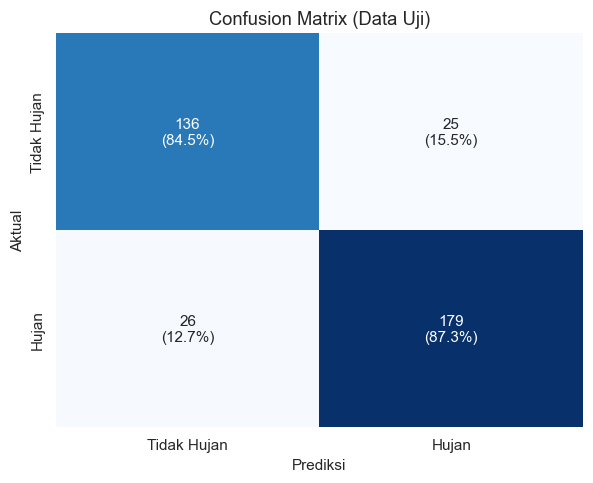

TN=136  FP=25  FN=26  TP=179


In [ ]:
cm = confusion_matrix(y_test, y_pred)
cm_persen = cm / cm.sum(axis=1, keepdims=True)
anotasi = np.array([[f"{cm[i, j]}\n({cm_persen[i, j]:.1%})" for j in range(2)] for i in range(2)])

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=anotasi, fmt="", cmap="Blues", cbar=False,
            xticklabels=["Tidak Hujan", "Hujan"], yticklabels=["Tidak Hujan", "Hujan"])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix (Data Uji)")
plt.tight_layout()
plt.savefig("output/05_confusion_matrix.png", bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

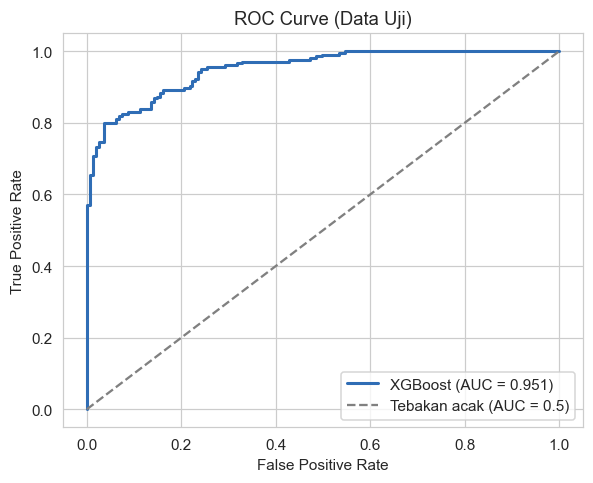

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, color="#2F6DB5", lw=2, label=f"XGBoost (AUC = {metrik['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Data Uji)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("output/06_roc_curve.png", bbox_inches="tight")
plt.show()

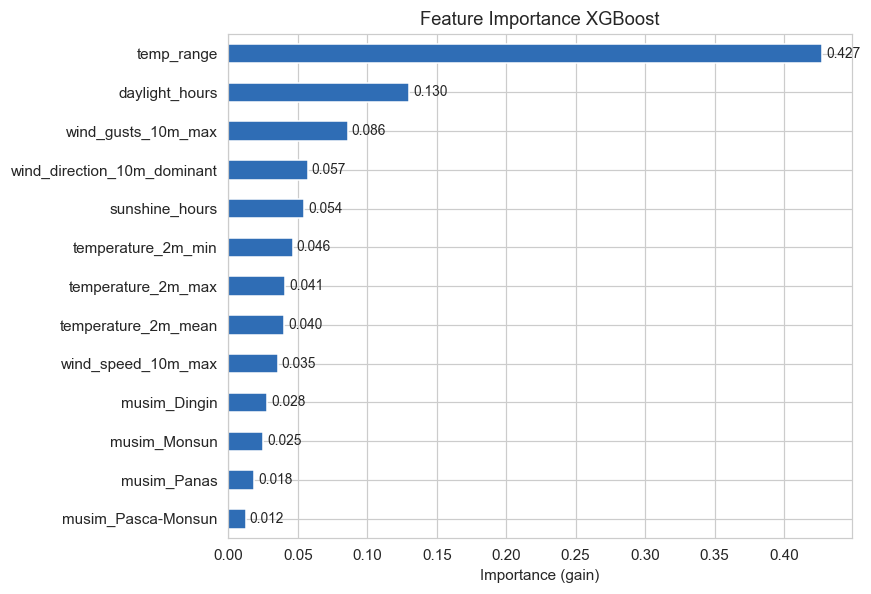

temp_range                     0.4273
daylight_hours                 0.1299
wind_gusts_10m_max             0.0858
wind_direction_10m_dominant    0.0570
sunshine_hours                 0.0544
temperature_2m_min             0.0462
temperature_2m_max             0.0406
temperature_2m_mean            0.0399
wind_speed_10m_max             0.0353
musim_Dingin                   0.0277
musim_Monsun                   0.0250
musim_Panas                    0.0185
musim_Pasca-Monsun             0.0124
dtype: float32


In [ ]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5.5))
ax = importance.plot(kind="barh", color="#2F6DB5")
for i, v in enumerate(importance.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
plt.xlabel("Importance (gain)")
plt.title("Feature Importance XGBoost")
plt.tight_layout()
plt.savefig("output/07_feature_importance.png", bbox_inches="tight")
plt.show()

print(importance.sort_values(ascending=False).round(4))

In [ ]:
# ============================================================
# CELL 17 - MENYIMPAN MODEL DAN ARTIFAK UNTUK STREAMLIT
# ============================================================

import pickle

# ------------------------------------------------------------
# 1. Simpan model XGBoost
# ------------------------------------------------------------

with open("model.pkl", "wb") as file:
    pickle.dump(model, file)


# ------------------------------------------------------------
# 2. Simpan nama dan urutan fitur
# ------------------------------------------------------------

feature_columns = X.columns.tolist()

with open("feature_columns.pkl", "wb") as file:
    pickle.dump(feature_columns, file)


# ------------------------------------------------------------
# 3. Simpan informasi kategori musim
# ------------------------------------------------------------

season_categories = MUSIM_LIST

with open("season_categories.pkl", "wb") as file:
    pickle.dump(season_categories, file)


# ------------------------------------------------------------
# 4. Simpan hasil evaluasi
# ------------------------------------------------------------

eval_artifacts = {
    "metrics_df": tabel_metrik,
    "cm": cm,
    "fpr": fpr,
    "tpr": tpr,
    "auc": metrik["ROC-AUC"],
    "importances": importance.reset_index(),
    "data": df,
    "feature_columns": feature_columns,
    "numeric_features": NUM_FEATURES,
    "categorical_features": CAT_FEATURES
}

with open("eval_data.pkl", "wb") as file:
    pickle.dump(eval_artifacts, file)


# ------------------------------------------------------------
# 5. Simpan informasi tambahan untuk prediksi manual
# ------------------------------------------------------------

model_info = {
    "numeric_features": NUM_FEATURES,
    "categorical_features": CAT_FEATURES,
    "feature_columns": feature_columns,
    "season_categories": season_categories
}

with open("model_info.pkl", "wb") as file:
    pickle.dump(model_info, file)


print("===================================================")
print("SEMUA FILE MODEL BERHASIL DISIMPAN")
print("===================================================")

print("✓ model.pkl")
print("✓ feature_columns.pkl")
print("✓ season_categories.pkl")
print("✓ eval_data.pkl")
print("✓ model_info.pkl")

SEMUA FILE MODEL BERHASIL DISIMPAN
✓ model.pkl
✓ feature_columns.pkl
✓ season_categories.pkl
✓ eval_data.pkl
✓ model_info.pkl


In [ ]:
# ============================================================
# CELL 18 - VERIFIKASI FILE PKL
# ============================================================

import os
import pickle

files_to_check = [
    "model.pkl",
    "feature_columns.pkl",
    "season_categories.pkl",
    "eval_data.pkl",
    "model_info.pkl"
]

print("Pemeriksaan file:")

for filename in files_to_check:

    if os.path.exists(filename):

        file_size = os.path.getsize(filename)

        print(
            f"✓ {filename} "
            f"({file_size / 1024:.2f} KB)"
        )

    else:

        print(
            f"✗ {filename} tidak ditemukan"
        )

Pemeriksaan file:
✓ model.pkl (182.51 KB)
✓ feature_columns.pkl (0.26 KB)
✓ season_categories.pkl (0.06 KB)
✓ eval_data.pkl (311.69 KB)
✓ model_info.pkl (0.54 KB)
